In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [6]:
df = pd.read_csv('2022mlbteams.csv')
df = df.drop([30, 31])
df = df.drop(columns=['#Bat', 'Tm'])
df

,BatAge,R/G,G,PA,AB,R,H,2B,3B,HR,...,OPS,OPS+,TB,GDP,HBP,SH,SF,IBB,LOB,PO
0,26.5,4.33,162,6027,5351,702,1232,262,24,173,...,0.689,95,2061,97,60,31,50,14,1039,0.0
1,27.5,4.87,162,6082,5509,789,1394,298,11,243,...,0.761,109,2443,103,66,1,36,13,1030,1.0
2,27.0,4.16,162,6049,5429,674,1281,275,25,171,...,0.695,99,2119,95,83,12,43,10,1095,0.0
3,28.8,4.54,162,6144,5539,735,1427,352,12,155,...,0.731,102,2268,131,63,12,50,23,1133,0.0
4,27.9,4.06,162,6072,5425,657,1293,265,31,159,...,0.698,94,2097,130,84,19,36,16,1100,0.0
5,29.3,4.23,162,6123,5611,686,1435,272,9,149,...,0.698,97,2172,127,73,16,35,9,1117,0.0
6,29.4,4.00,162,5978,5380,648,1264,235,18,156,...,0.676,85,2003,127,92,12,33,6,1020,0.0
7,25.9,4.31,162,6163,5558,698,1410,273,31,127,...,0.699,102,2126,119,81,22,52,36,1156,1.0
8,29.1,4.31,162,6105,5540,698,1408,280,34,149,...,0.713,91,2203,139,61,10,40,10,1113,0.0
9,27.9,3.44,162,5870,5378,557,1240,235,27,110,...,0.632,82,1859,108,58,10,44,8,1015,0.0


In [7]:
x = df.iloc[:, 0:27]
y = df.iloc[:, 27]
x.shape, y.shape

((30, 27), (30,))

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=21)

In [9]:
scale = StandardScaler()
x_train = scale.fit_transform(x_train)
x_train = pd.DataFrame(x_train, columns=df.columns[:-1])
x_train.head()

,BatAge,R/G,G,PA,AB,R,H,2B,3B,HR,...,SLG,OPS,OPS+,TB,GDP,HBP,SH,SF,IBB,LOB
0,-0.032987,-1.708056,0.0,-2.105939,-2.081256,-1.713743,-2.374828,-0.496051,-1.023632,-1.011987,...,-1.991887,-2.198327,-1.578618,-2.106985,-0.269665,-0.590017,1.201209,-1.197071,-1.046090,-2.339528
1,-2.144152,0.099809,0.0,1.070839,1.875833,0.099373,1.267922,0.293245,1.101096,-1.305671,...,-0.440312,-0.149673,0.310476,-0.112710,0.352639,0.776338,1.201209,1.465682,2.309111,1.440098
2,-0.296883,0.212801,0.0,-0.348122,0.578427,0.224896,-0.144856,-1.318234,-0.359654,0.779487,...,0.062902,-0.233865,-0.319222,0.163314,-1.949889,-1.335301,-0.462003,-0.496347,-0.467607,-1.571476
3,-1.088570,-0.713730,0.0,-0.549318,-0.086494,-0.709556,0.118309,-0.561825,2.030664,-0.982618,...,-0.566115,-0.514502,-0.634071,-0.540547,-0.767509,-1.273194,0.924007,0.344523,-1.046090,0.126324
4,1.638352,1.613896,0.0,1.166142,-0.329757,1.619600,-0.144856,-1.285346,-1.953200,2.424118,...,1.362870,1.309641,1.359973,1.163902,0.477100,0.093161,0.092401,-0.075912,2.309111,0.166748


In [10]:
pca1 = PCA()
x_pca1 = pca1.fit_transform(x_train)
x_pca1.shape

(24, 24)

In [11]:
pca1.explained_variance_

array([1.36505043e+01, 3.51517191e+00, 2.44025722e+00, 1.62138852e+00,
       1.28925022e+00, 9.78777928e-01, 9.59534446e-01, 6.63617885e-01,
       4.81017117e-01, 4.12601757e-01, 3.42447262e-01, 3.16291725e-01,
       2.04586998e-01, 1.06781659e-01, 8.81272121e-02, 3.72110088e-02,
       1.70317824e-02, 4.18080542e-03, 1.25510861e-03, 2.53271200e-04,
       1.21783859e-04, 1.74651823e-05, 7.44330331e-06, 9.05176495e-33])

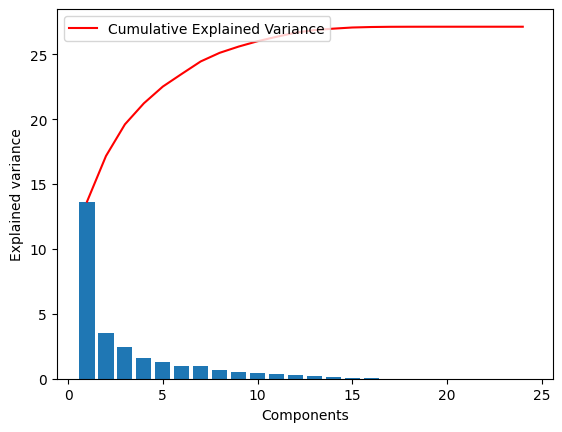

In [27]:
plt.bar(range(1, len(pca1.explained_variance_) + 1), pca1.explained_variance_)
plt.ylabel('Explained variance')
plt.xlabel('Components')
plt.plot(range(1, len(pca1.explained_variance_) + 1),
         np.cumsum(pca1.explained_variance_),
         c='red',
         label="Cumulative Explained Variance")
plt.legend(loc='upper left')

In [28]:
pca2 = PCA(0.95)
x_pca2 = pca2.fit_transform(x_train)
x_pca2.shape

(24, 10)

In [30]:
print(pca2.explained_variance_ratio_)
np.sum(pca2.explained_variance_ratio_)

[0.50314359 0.12956563 0.08994538 0.05976272 0.04752044 0.03607675
 0.03536746 0.02446027 0.0177298  0.01520808]


0.9587801104522713

In [13]:
pca2c = PCA(n_components=2)
x_pca2c = pca2c.fit_transform(x_train)

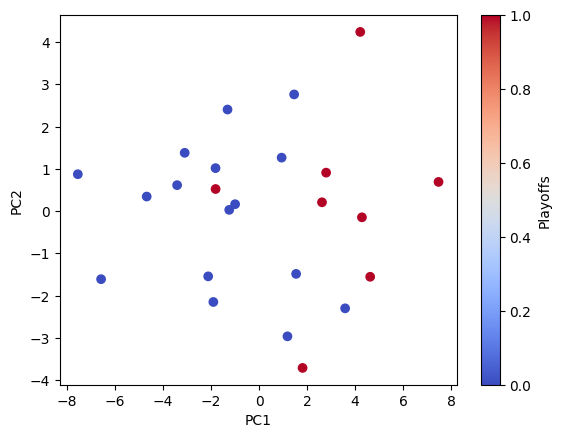

In [14]:
plt.figure()
scatter = plt.scatter(x_pca2c[:, 0], x_pca2c[:, 1], c=y_train, cmap='coolwarm')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(scatter, label='Playoffs')
plt.show()

In [16]:
pca3c = PCA(n_components=3)
x_pca3c = pca3c.fit_transform(x_train)

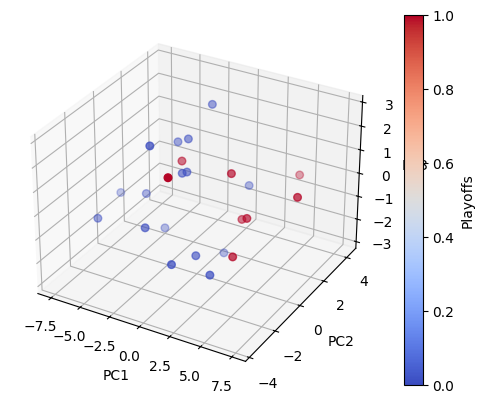

In [17]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(x_pca3c[:, 0], x_pca3c[:, 1], x_pca3c[:, 2], c=y_train, cmap='coolwarm', s=30)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.colorbar(scatter, label='Playoffs')
plt.show()